In [1]:
import scanpy as sc
local_dir = "./Data/Pert/STATE/Replogle_Nadig/"
raw_adata = sc.read_h5ad(local_dir+"/replogle.h5ad", backed="r")
raw_adata

/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/scanpy/_utils/__init__.py:27: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/scanpy/__init__.py:36: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/scanpy/readwrite.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/Users/aliee01/Enter/envs/sc-env/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refr

AnnData object with n_obs × n_vars = 643413 × 6642 backed at 'Data/Pert/STATE/Replogle_Nadig/replogle.h5ad'
    obs: 'gem_group', 'gene', 'gene_id', 'transcript', 'gene_transcript', 'sgID_AB', 'mitopercent', 'UMI_count', 'z_gemgroup_UMI', 'cell_line'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_hvg'

In [27]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from gears import PertData, GEARS

DATA_DIR = "./data"           # GEARS will download RPE1 data here 
OUT_DIR = Path("./gears_rpe1_run")
OUT_DIR.mkdir(exist_ok=True)
 
SPLIT = "simulation"          
SEED = 1
BATCH_SIZE = 32
TEST_BATCH_SIZE = 128

pert_data = PertData(DATA_DIR)
pert_data.load(data_name="replogle_rpe1_essential")
pert_data.prepare_split(split=SPLIT, seed=SEED)
pert_data.get_dataloader(batch_size=BATCH_SIZE, test_batch_size=TEST_BATCH_SIZE)
 
pert_data

Found local copy...
Found local copy...
Found local copy...
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['C14orf178+ctrl' 'C7orf26+ctrl' 'GNB1L+ctrl' 'ALG1L+ctrl' 'FAU+ctrl'
 'RPS10-NUDT3+ctrl' 'FAM102B+ctrl' 'SEM1+ctrl' 'AC118549.1+ctrl']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:0
combo_seen1:0
combo_seen2:0
unseen_single:384
Done!
Creating dataloaders....
Done!


here1


In [29]:
def conditions_to_genes(conditions):
    genes = []
    for c in conditions:
        if c == "ctrl":
            continue
        g = [x for x in c.split("+") if x != "ctrl"]
        genes.extend(g)
    return sorted(set(genes))
    
val_genes = conditions_to_genes(pert_data.set2conditions["val"])
test_genes = conditions_to_genes(pert_data.set2conditions["test"])

toml_content = f'''[datasets]
replogle_nadig = "/mnt/scratche/slow/halab/Hana/Data/Pert/STATE/Replogle_Nadig/"

[training]
replogle_nadig = "train"

[fewshot]
[fewshot."replogle_nadig.rpe1"]
val = {val_genes!r}
test = {test_genes!r}
'''

with open("/mnt/scratche/slow/halab/Hana/gears_matched_full_split.toml", "w") as f:
    f.write(toml_content)

print(toml_content)

[datasets]
replogle_nadig = "/mnt/scratche/slow/halab/Hana/Data/Pert/STATE/Replogle_Nadig/"

[training]
replogle_nadig = "train"

[fewshot]
[fewshot."replogle_nadig.rpe1"]
val = ['ADAM10', 'ALDOA', 'ANAPC13', 'BRF2', 'CCAR1', 'CENPK', 'CENPN', 'CHMP6', 'CIAPIN1', 'CLOCK', 'CLTC', 'CNOT1', 'CPNE7', 'CSDE1', 'CUL3', 'DDB1', 'DDX54', 'DDX55', 'DOLK', 'DSN1', 'EDC4', 'EIF2S3', 'EIF3CL', 'EIF3J', 'EIF4H', 'EIF5A', 'FAM50A', 'FARSB', 'FASN', 'FBXO42', 'FYN', 'GTF2E1', 'ICE1', 'INO80B', 'IPO11', 'KAT5', 'LSG1', 'LSM5', 'MASTL', 'MAT2A', 'MAX', 'MED22', 'MED7', 'MFAP1', 'MNAT1', 'MRGBP', 'MRPL34', 'MRPL36', 'NACA', 'NCAPH', 'NMD3', 'NOB1', 'NOL8', 'NUB1', 'NUP107', 'NUP85', 'OSTC', 'PABPC4', 'PAXBP1', 'PCNX3', 'PDCD7', 'PDHA1', 'PELP1', 'PEX19', 'PLRG1', 'POLR3C', 'PRELID3B', 'PRIM1', 'PRPF38A', 'PSMA2', 'PSMA6', 'PSMD11', 'RABGGTA', 'RAC1', 'RAD17', 'RNGTT', 'RPL26', 'RPL9', 'RPS24', 'RPS27A', 'RTRAF', 'SAE1', 'SDHC', 'SERBP1', 'SF3B4', 'SIN3A', 'SKP1', 'SLC25A42', 'SMARCB1', 'SMC3', 'SNRNP25

In [31]:
raw_adata.obs.cell_line.value_counts()

cell_line
k562      188590
jurkat    184470
rpe1      173737
hepg2      96616
Name: count, dtype: int64

In [32]:
raw_adata

AnnData object with n_obs × n_vars = 643413 × 6642 backed at 'Data/Pert/STATE/Replogle_Nadig/Others/replogle.h5ad'
    obs: 'gem_group', 'gene', 'gene_id', 'transcript', 'gene_transcript', 'sgID_AB', 'mitopercent', 'UMI_count', 'z_gemgroup_UMI', 'cell_line'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_hvg'

## Prediction results

In [85]:
import scanpy as sc

pred = sc.read_h5ad("/Users/aliee01/state_rpe1_matched_5000/gears_matched_run/eval_final.ckpt/adata_pred.h5ad")
real = sc.read_h5ad("/Users/aliee01/state_rpe1_matched_5000/gears_matched_run/eval_final.ckpt/adata_real.h5ad")

print("Predicted:", pred.shape)
print("Real:", real.shape)
print("\nPred obs columns:", pred.obs.columns.tolist())
print("Real obs columns:", real.obs.columns.tolist())
print("\nPred obs head:\n", pred.obs.head())

Predicted: (46618, 6642)
Real: (46618, 6642)

Pred obs columns: ['gene', 'cell_line', 'gem_group', 'pert_cell_barcode', 'ctrl_cell_barcode']
Real obs columns: ['gene', 'cell_line', 'gem_group', 'pert_cell_barcode', 'ctrl_cell_barcode']

Pred obs head:
    gene cell_line gem_group pert_cell_barcode ctrl_cell_barcode
0  TAF8      rpe1        43       cell_481740       cell_628148
1  TAF8      rpe1        54       cell_604074       cell_496989
2  TAF8      rpe1         1       cell_494578       cell_475818
3  TAF8      rpe1        38       cell_499435       cell_536982
4  TAF8      rpe1        45       cell_549595       cell_529527


In [86]:
real = real[~real.obs.gene.isin(['non-targeting'])].copy()

In [87]:
pred = pred[~pred.obs.gene.isin(['non-targeting'])].copy()

In [88]:
import numpy as np
import pandas as pd

def normalize_log(X, target_sum=1e4):
    X = np.asarray(X, dtype=float)
    totals = X.sum(axis=1, keepdims=True)
    totals[totals == 0] = 1
    return np.log1p(X / totals * target_sum)

results_state = []
for cond in pred.obs['gene'].unique():
    if cond!="non-targeting":
        pred_mask = pred.obs['gene'] == cond
        real_mask = real.obs['gene'] == cond

        pred_sub = pred[pred_mask].X
        real_sub = real[real_mask].X
        pred_sub = pred_sub.toarray() if hasattr(pred_sub, "toarray") else pred_sub
        real_sub = real_sub.toarray() if hasattr(real_sub, "toarray") else real_sub

        if pred_sub.shape[0] < 5 or real_sub.shape[0] < 5:
            continue

        results_state.append({
            "condition": cond,
            "total_var_pred": np.var(pred_sub, axis=0).sum(),
            "total_var_real": np.var(real_sub, axis=0).sum(),
            "n_pred_cells": pred_sub.shape[0],
            "n_real_cells": real_sub.shape[0],
        })

state_var_df = pd.DataFrame(results_state).set_index("condition")
print(f"Built state_var_df with {len(state_var_df)} rows")
print(state_var_df.describe())

Built state_var_df with 312 rows
       total_var_pred  total_var_real  n_pred_cells  n_real_cells
count      312.000000      312.000000    312.000000    312.000000
mean       868.581726      923.461121    112.605769    112.605769
std         58.104599      111.595421    229.554374    229.554374
min        617.740601      642.564697     30.000000     30.000000
25%        847.914932      860.714905     48.000000     48.000000
50%        864.892334      924.670807     72.000000     72.000000
75%        888.060394      979.266220    108.250000    108.250000
max       1092.628906     1342.392334   3458.000000   3458.000000


In [90]:
from scipy.stats import spearmanr

# Re-run state_var_df construction with the ctrl/non-targeting exclusion first,
# then check the correlation
rho, p = spearmanr(state_var_df["n_real_cells"], state_var_df["total_var_pred"])
print(f"n_real_cells vs total_var_pred: rho={rho:.3f}, p={p:.4g}")

rho2, p2 = spearmanr(state_var_df["n_real_cells"], state_var_df["total_var_real"])
print(f"n_real_cells vs total_var_real: rho={rho2:.3f}, p={p2:.4g}")

n_real_cells vs total_var_pred: rho=0.067, p=0.239
n_real_cells vs total_var_real: rho=0.133, p=0.01865


In [91]:
from scipy.stats import pearsonr

r_full, p_full = pearsonr(state_var_df["total_var_real"], state_var_df["total_var_pred"])
print(f"Full (n={len(state_var_df)}): r={r_full:.3f}, p={p_full:.4g}")

state_var_df_filtered = state_var_df[state_var_df["n_real_cells"] >= 10]
r_filt, p_filt = pearsonr(state_var_df_filtered["total_var_real"], state_var_df_filtered["total_var_pred"])
print(f"Filtered n>=10 (n={len(state_var_df_filtered)}): r={r_filt:.3f}, p={p_filt:.4g}")


Full (n=312): r=0.414, p=2.427e-14
Filtered n>=50 (n=312): r=0.414, p=2.427e-14


In [92]:
coef = np.polyfit(state_var_df["total_var_real"], state_var_df["total_var_pred"], 1)
print(f"Slope: {coef[0]:.3f}, intercept: {coef[1]:.1f}")

Slope: 0.215, intercept: 669.6


In [93]:
df = state_var_df_filtered.copy()   # EDIT this to match your actual variable name

pred_col = "total_var_pred"
real_col = "total_var_real"

from scipy.stats import pearsonr
r, p = pearsonr(df[real_col], df[pred_col])
slope, intercept = np.polyfit(df[real_col], df[pred_col], 1)

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import pearsonr, gaussian_kde

df = state_var_df_filtered.copy()      # must have total_var_real, total_var_pred
# canonical_data = sc.read('./Data/Pert/STATE/Replogle_Nadig/processed_data/replogle.h5ad')           # STATE's full preprocessed dataset (all cell lines)
canonical_data = sc.read('./Data/Pert/STATE/Replogle_Nadig/processed_data/replogle_full_trained.h5ad')
pred_data = pred                        # STATE's eval prediction output (has cin_damage_score)


In [95]:
# canonical_data = sc.read('./Data/Pert/STATE/Replogle_Nadig/processed_data/replogle_full_trained.h5ad')
# canonical_data_rhp1 = canonical_data[canonical_data.obs.cell_line=='rpe1']
# canonical_data_rhp1_test = canonical_data_rhp1[canonical_data_rhp1.obs.gene.isin(set(real.obs.gene))]

In [96]:
import json

val_genes = set(json.load(open("canonical_val_genes.json")))
test_genes = set(json.load(open("canonical_test_genes.json")))

all_rpe1_genes = set(canonical_data.obs.loc[canonical_data.obs["cell_line"]=="rpe1", "gene"].unique())
train_genes_set = all_rpe1_genes - val_genes - test_genes - {"non-targeting"}

print(f"Train genes: {len(train_genes_set)}")

Train genes: 1097


In [97]:
cin_damage_genes = [
    "UBE2T", "PARP1", "XRCC5", "SMC4", "NCAPG", "MAD2L1", "NPM1", "RPA3",
    "MCM7", "PRKDC", "SMC2", "KIF20B", "RRM1", "FEN1", "NCAPD2", "CBX5",
    "NUSAP1", "TOP2A", "BRCA1", "BIRC5", "SMC1A",
]

# Use var_names directly -- confirm they're gene symbols, not Ensembl IDs
print(pred.var_names[:5].tolist())
pred.var_names = canonical_data.var_names
real.var_names = canonical_data.var_names

genes_present_pred = [g for g in cin_damage_genes if g in pred.var_names]
genes_present_real = [g for g in cin_damage_genes if g in real.var_names]
print(f"Pred: {len(genes_present_pred)}/{len(cin_damage_genes)} found")
print(f"Real: {len(genes_present_real)}/{len(cin_damage_genes)} found")



sc.tl.score_genes(pred, gene_list=genes_present_pred, score_name="cin_damage_score")
sc.tl.score_genes(real, gene_list=genes_present_real, score_name="cin_damage_score")

['0', '1', '2', '3', '4']
Pred: 21/21 found
Real: 21/21 found


In [98]:
sc.tl.score_genes(canonical_data, gene_list=genes_present_real, score_name="cin_damage_score")

In [99]:
import scanpy as sc

raw_adata = sc.read('./Data/Pert/STATE/Replogle_Nadig/replogle.h5ad')
raw_adata

AnnData object with n_obs × n_vars = 643413 × 6642
    obs: 'gem_group', 'gene', 'gene_id', 'transcript', 'gene_transcript', 'sgID_AB', 'mitopercent', 'UMI_count', 'z_gemgroup_UMI', 'cell_line'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_hvg'

In [100]:
raw_adata = raw_adata.to_memory()
sc.tl.score_genes(raw_adata, gene_list=genes_present_real, score_name="cin_damage_score")

In [101]:
raw_adata.obs.cell_line

cell_barcode
AAACCCAAGAATAGTC-3     hepg2
AAACCCAAGAGGTATT-55    hepg2
AAACCCAAGAGTGACC-39    hepg2
AAACCCAAGATGGCAC-43    hepg2
AAACCCAAGCAACAAT-16    hepg2
                       ...  
TTTGTTGTCTGATGGT-14     rpe1
TTTGTTGTCTGCACCT-44     rpe1
TTTGTTGTCTGGGCAC-32     rpe1
TTTGTTGTCTGTCCCA-37     rpe1
TTTGTTGTCTTTCCGG-22     rpe1
Name: cell_line, Length: 643413, dtype: category
Categories (4, object): ['hepg2', 'jurkat', 'k562', 'rpe1']

In [103]:
import anndata as ad
official_pred_scores_state = []

for cond in pred.obs["gene"].unique():
    pred_sub = pred[pred.obs["gene"] == cond].X
    pred_sub = pred_sub.toarray() if hasattr(pred_sub, "toarray") else pred_sub

    mean_vector = pred_sub.mean(axis=0).reshape(1, -1)

    tmp = ad.AnnData(X=mean_vector, var=pd.DataFrame(index=pred.var_names))
    sc.tl.score_genes(tmp, gene_list=genes_present_real, score_name="cin_damage_score")
    official_pred_scores_state.append(tmp.obs["cin_damage_score"].values[0])

official_pred_scores_state = np.array(official_pred_scores_state)
official_mean_state = official_pred_scores_state.mean()
print(f"STATE mean-prediction CIN (across {len(official_pred_scores_state)} conditions): {official_mean_state:.4f}")

STATE mean-prediction CIN (across 312 conditions): -0.0381


/tmp/ipykernel_2037311/2446526490.py:105: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Summary: r=0.414, p=2.427e-14, slope=0.215, n=312


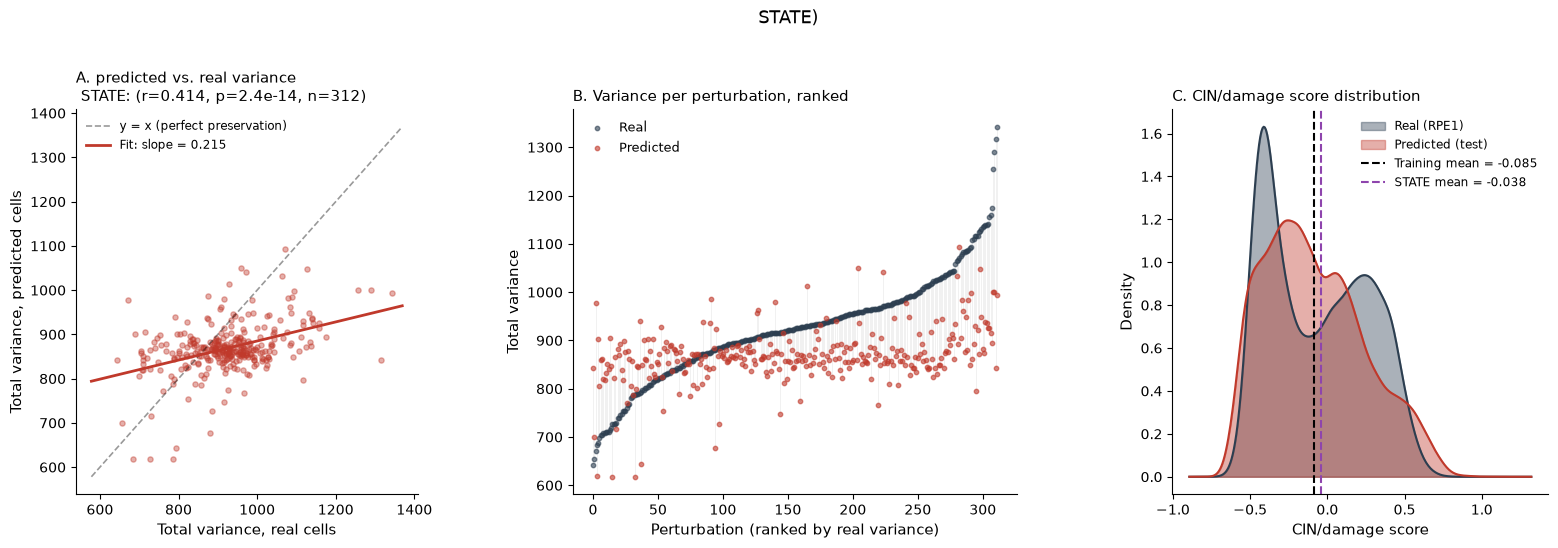

In [104]:
train_genes = train_genes_set           # set of RPE1 training gene names

pred_col = "total_var_pred"
real_col = "total_var_real"

REAL_COLOR = "#2c3e50"
PRED_COLOR = "#c0392b" #27ae60"
MEAN_COLOR = "#8e44ad"
MODEL_NAME = "STATE"

# ============================================================
# Compute everything needed, from scratch, no external state assumed
# ============================================================

# --- Stats for Panel A/B ---
r, p = pearsonr(df[real_col], df[pred_col])
slope, intercept = np.polyfit(df[real_col], df[pred_col], 1)

# --- Training mean CIN score (RPE1, training genes only) ---
train_mean_cin = raw_adata.obs.loc[
    raw_adata.obs["gene"].isin(train_genes) , # & (raw_adata.obs["cell_line"] == "rpe1"),
    "cin_damage_score"
].mean()

# --- Real / predicted CIN score arrays for Panel C ---
rpe1_real_scores = real.obs["cin_damage_score"].values #canonical_data.obs.loc[canonical_data.obs["cell_line"] == "rpe1", "cin_damage_score"].values
pred_scores = pred.obs["cin_damage_score"].values

# --- STATE's mean-prediction CIN score, per condition ---
official_pred_scores_state = []
for cond in pred.obs["gene"].unique():
    pred_sub = pred[pred.obs["gene"] == cond].X
    pred_sub = pred_sub.toarray() if hasattr(pred_sub, "toarray") else pred_sub
    mean_vector = pred_sub.mean(axis=0).reshape(1, -1)
    tmp = ad.AnnData(X=mean_vector, var=pd.DataFrame(index=pred.var_names))
    sc.tl.score_genes(tmp, gene_list=genes_present_real, score_name="cin_damage_score")
    official_pred_scores_state.append(tmp.obs["cin_damage_score"].values[0])
official_mean_state = np.mean(official_pred_scores_state)

# ============================================================
# Build figure
# ============================================================

fig = plt.figure(figsize=(19, 5))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.3, 1.1], wspace=0.4)

# Panel A: slope plot 
axA = fig.add_subplot(gs[0])
axA.scatter(df[real_col], df[pred_col], s=14, alpha=0.4, color=PRED_COLOR)
lims = [df[real_col].min() * 0.9, df[real_col].max() * 1.02]
axA.plot(lims, lims, 'k--', alpha=0.4, lw=1.2, label="y = x (perfect preservation)")
fit_x = np.array(lims)
fit_y = intercept + slope * fit_x
axA.plot(fit_x, fit_y, color=PRED_COLOR, lw=2, label=f"Fit: slope = {slope:.3f}")
axA.set_xlabel("Total variance, real cells", fontsize=10.5)
axA.set_ylabel("Total variance, predicted cells", fontsize=10.5)
axA.set_title(f"A. predicted vs. real variance\n {MODEL_NAME}: (r={r:.3f}, p={p:.2g}, n={len(df)})",
              fontsize=11, loc="left")
axA.legend(fontsize=8.5, frameon=False, loc="upper left")
axA.spines[['top', 'right']].set_visible(False)

# Panel B: sorted variance-per-perturbation 
axB = fig.add_subplot(gs[1])
df_sorted = df.sort_values(real_col).reset_index(drop=True)
x = np.arange(len(df_sorted))
axB.scatter(x, df_sorted[real_col], s=10, alpha=0.6, color=REAL_COLOR, label="Real")
axB.scatter(x, df_sorted[pred_col], s=10, alpha=0.6, color=PRED_COLOR, label="Predicted")
for i in range(len(df_sorted)):
    axB.plot([x[i], x[i]], [df_sorted[real_col].iloc[i], df_sorted[pred_col].iloc[i]],
             color="gray", alpha=0.15, lw=0.5, zorder=0)
axB.set_xlabel("Perturbation (ranked by real variance)", fontsize=10.5)
axB.set_ylabel("Total variance", fontsize=10.5)
axB.set_title("B. Variance per perturbation, ranked", fontsize=11, loc="left")
axB.legend(fontsize=9, frameon=False, loc="upper left")
axB.spines[['top', 'right']].set_visible(False)

# Panel C: CIN score density
axC = fig.add_subplot(gs[2])
x_range = np.linspace(
    min(rpe1_real_scores.min(), pred_scores.min(), official_mean_state) - 0.2,
    max(rpe1_real_scores.max(), pred_scores.max(), official_mean_state) + 0.2,
    300
)
kde_real = gaussian_kde(rpe1_real_scores)
kde_pred = gaussian_kde(pred_scores)

axC.fill_between(x_range, kde_real(x_range), alpha=0.4, color=REAL_COLOR, label="Real (RPE1)")
axC.plot(x_range, kde_real(x_range), color=REAL_COLOR, lw=1.5)
axC.fill_between(x_range, kde_pred(x_range), alpha=0.4, color=PRED_COLOR, label="Predicted (test)")
axC.plot(x_range, kde_pred(x_range), color=PRED_COLOR, lw=1.5)
axC.axvline(train_mean_cin, color="black", linestyle="--", linewidth=1.5,
            label=f"Training mean = {train_mean_cin:.3f}")
axC.axvline(official_mean_state, color=MEAN_COLOR, linestyle="--", linewidth=1.5,
            label=f"STATE mean = {official_mean_state:.3f}")

axC.set_xlabel("CIN/damage score", fontsize=10.5)
axC.set_ylabel("Density", fontsize=10.5)
axC.set_title("C. CIN/damage score distribution", fontsize=11, loc="left")
axC.legend(frameon=False, fontsize=8.5)
axC.spines[['top', 'right']].set_visible(False)

fig.suptitle(f"{MODEL_NAME})",
             fontsize=13, y=1.08)

plt.tight_layout()
plt.savefig("state_draft_figure_3panel.pdf", dpi=220, bbox_inches="tight", transparent=True)
print(f"Summary: r={r:.3f}, p={p:.4g}, slope={slope:.3f}, n={len(df)}")

In [40]:
from sklearn.mixture import GaussianMixture

def bic_comparison(scores):
    scores_r = scores.reshape(-1, 1)
    gmm1 = GaussianMixture(n_components=1, random_state=0).fit(scores_r)
    gmm2 = GaussianMixture(n_components=2, random_state=0).fit(scores_r)
    return gmm1.bic(scores_r) - gmm2.bic(scores_r)  # positive = 2-component model preferred

print(f"Real: BIC improvement from 2 components: {bic_comparison(all_real_scores):.1f}")
print(f"Predicted: BIC improvement from 2 components: {bic_comparison(all_pred_scores):.1f}")

Real: BIC improvement from 2 components: 11895.6
Predicted: BIC improvement from 2 components: 3005.9
